<a href="https://colab.research.google.com/github/shaunyttan-cell/MD5063_SHAUN_TAN_YAN_TAT_25119033_Assigment-3/blob/main/MDM5063_25119033_Shaun_Tan_Yan_Tat_Assessment_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q scikit-learn==1.9.1

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 51.6 MB/s eta 0:00:00


In [ ]:
import sklearn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# Chart style: white background with dark, bold titles and labels
plt.style.use("default")
plt.rcParams.update({
    "text.color": "#111111", "axes.labelcolor": "#111111", "axes.edgecolor": "#444444",
    "xtick.color": "#111111", "ytick.color": "#111111",
    "axes.titleweight": "bold", "axes.labelweight": "bold", "figure.titleweight": "bold",
    "figure.dpi": 120})
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # one colour per model
blue = colors[0]

print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.9.1


In [ ]:
# load the dataset from UCI repo
!pip install -q ucimlrepo
from ucimlrepo import fetch_ucirepo

uci = fetch_ucirepo(id=468)
df = pd.concat([uci.data.features, uci.data.targets], axis=1)

print("Shape:", df.shape)
print(df.dtypes)

Shape: (12330, 18)
Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                       object
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                 object
Weekend                       bool
Revenue                       bool
dtype: object


In [ ]:
# Data Quality Checks
# Missing values in each column
print("Missing values per column:")
print(df.isna().sum())
print("\nTotal missing values:", df.isna().sum().sum())

# Duplicate rows and month labels
print("Duplicate rows:", df.duplicated().sum())
print("Month labels:", sorted(df["Month"].unique()))

Missing values per column:
Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

Total missing values: 0
Duplicate rows: 125
Month labels: ['Aug', 'Dec', 'Feb', 'Jul', 'June', 'Mar', 'May', 'Nov', 'Oct', 'Sep']


In [ ]:
# Statistics for numeric attributes
# Numeric columns
num_cols = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
            "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates", "PageValues", "SpecialDay"]

# Mean, median, min, max, standard deviation, skewness, mode and missing values
stats = df[num_cols].agg(["mean", "median", "min", "max", "std", "skew"]).T
stats["mode"] = df[num_cols].mode().iloc[0]
stats["missing"] = df[num_cols].isna().sum()
stats["zero_%"] = (df[num_cols] == 0).mean() * 100
stats.round(3)

,mean,median,min,max,std,skew,mode,missing,zero_%
Administrative,2.315,1.000,0.0,27.000,3.322,1.960,0.0,0,46.780
Administrative_Duration,80.819,7.500,0.0,3398.750,176.779,5.616,0.0,0,47.875
Informational,0.504,0.000,0.0,24.000,1.270,4.036,0.0,0,78.662
Informational_Duration,34.472,0.000,0.0,2549.375,140.749,7.579,0.0,0,80.495
ProductRelated,31.731,18.000,0.0,705.000,44.476,4.342,1.0,0,0.308
ProductRelated_Duration,1194.746,598.937,0.0,63973.522,1913.669,7.263,0.0,0,6.123
BounceRates,0.022,0.003,0.0,0.200,0.048,2.948,0.0,0,44.753
ExitRates,0.043,0.025,0.0,0.200,0.049,2.149,0.2,0,0.616
PageValues,5.889,0.000,0.0,361.764,18.568,6.383,0.0,0,77.859
SpecialDay,0.061,0.000,0.0,1.000,0.199,3.303,0.0,0,89.854


In [ ]:
# Summary of categorical attributes
# Categorical and boolean columns
cat_cols = ["Month", "VisitorType", "OperatingSystems", "Browser", "Region", "TrafficType", "Weekend", "Revenue"]

# Number of levels, mode and missing values
cat_summary = pd.DataFrame({
    "levels": df[cat_cols].nunique(),
    "mode": df[cat_cols].mode().iloc[0],
    "mode_%": [round(df[c].value_counts(normalize=True).iloc[0] * 100, 1) for c in cat_cols],
    "missing": df[cat_cols].isna().sum()})
cat_summary

,levels,mode,mode_%,missing
Month,10,May,27.3,0
VisitorType,3,Returning_Visitor,85.6,0
OperatingSystems,8,2,53.5,0
Browser,13,2,64.6,0
Region,9,1,38.8,0
TrafficType,20,2,31.7,0
Weekend,2,False,76.7,0
Revenue,2,False,84.5,0


Revenue
False    10422
True      1908
Name: count, dtype: int64
Purchase rate: 15.47%


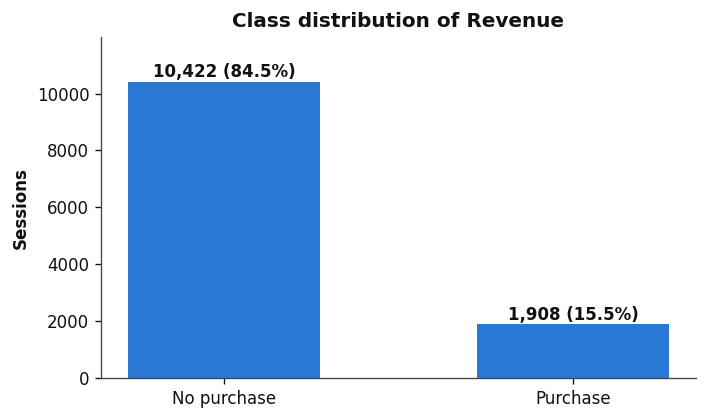

In [ ]:
# Target Variable - Revenue
# Count of sessions with and without a purchase
counts = df["Revenue"].value_counts()
print(counts)
print("Purchase rate: %.2f%%" % (df["Revenue"].mean() * 100))

# Bar chart of the class distribution
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.bar(["No purchase", "Purchase"], counts.values, color=blue, width=0.55)
for i, v in enumerate(counts.values):
    ax.text(i, v + 150, f"{v:,} ({v / len(df):.1%})", ha="center", fontsize=10, fontweight="bold")
ax.set_ylim(0, counts.max() * 1.15)
ax.set_ylabel("Sessions")
ax.set_title("Class distribution of Revenue")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

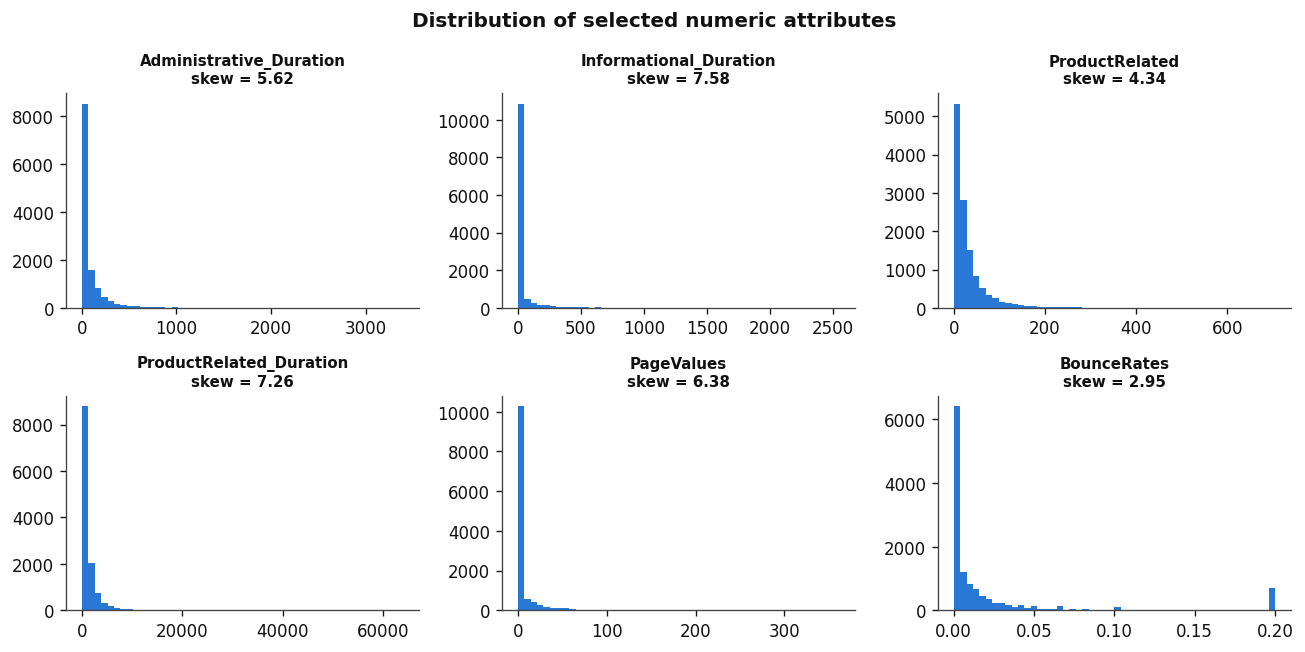

In [ ]:
# Distribution
# Histograms with the skewness of each attribute
plot_cols = ["Administrative_Duration", "Informational_Duration", "ProductRelated",
             "ProductRelated_Duration", "PageValues", "BounceRates"]
fig, axes = plt.subplots(2, 3, figsize=(11, 5.5))
for ax, col in zip(axes.ravel(), plot_cols):
    ax.hist(df[col], bins=50, color=blue)
    ax.set_title(f"{col}\nskew = {df[col].skew():.2f}", fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)
plt.suptitle("Distribution of selected numeric attributes")
plt.tight_layout()
plt.show()

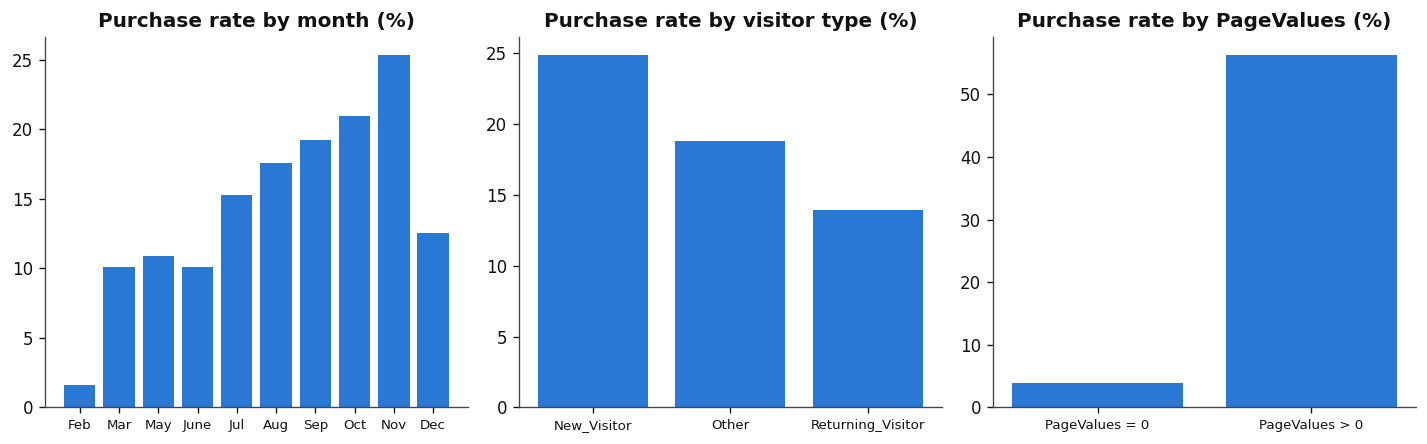

Month
Feb      1.6
Mar     10.1
May     10.9
June    10.1
Jul     15.3
Aug     17.6
Sep     19.2
Oct     20.9
Nov     25.4
Dec     12.5
Name: Revenue, dtype: float64
VisitorType
New_Visitor          24.9
Other                18.8
Returning_Visitor    13.9
Name: Revenue, dtype: float64
PageValues = 0     3.9
PageValues > 0    56.3
Name: Revenue, dtype: float64


In [ ]:
# Purchase rate (%) for each group
month_order = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
by_month = df.groupby("Month")["Revenue"].mean().reindex(month_order) * 100
by_visitor = df.groupby("VisitorType")["Revenue"].mean() * 100
by_pv = df.groupby(np.where(df["PageValues"] > 0, "PageValues > 0", "PageValues = 0"))["Revenue"].mean() * 100

# Bar charts
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
axes[0].bar(by_month.index, by_month.values, color=blue)
axes[0].set_title("Purchase rate by month (%)")
axes[1].bar(by_visitor.index, by_visitor.values, color=blue)
axes[1].set_title("Purchase rate by visitor type (%)")
axes[2].bar(by_pv.index, by_pv.values, color=blue)
axes[2].set_title("Purchase rate by PageValues (%)")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="x", labelsize=8)
plt.tight_layout()
plt.show()

print(by_month.round(1))
print(by_visitor.round(1))
print(by_pv.round(1))

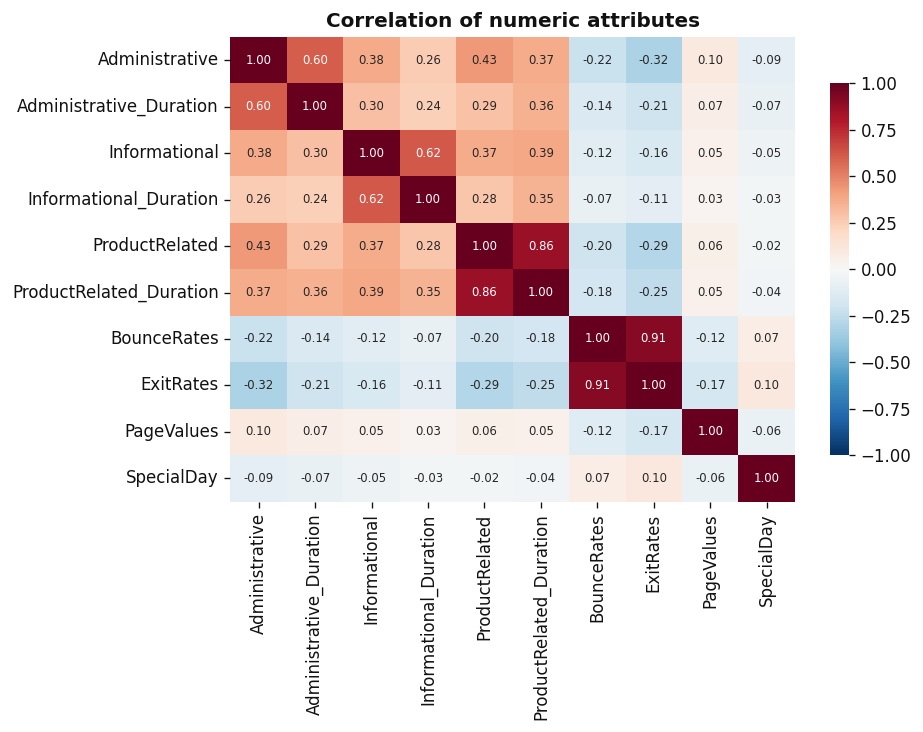

In [ ]:
# Correlation heatmap
plt.figure(figsize=(8, 6.2))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", vmin=-1, vmax=1,
            cmap="RdBu_r",
            annot_kws={"size": 7}, cbar_kws={"shrink": 0.8})
plt.title("Correlation of numeric attributes")
plt.tight_layout()
plt.show()

In [ ]:
# Data cleaning
# Remove duplicate rows
data = df.drop_duplicates().copy()
print("Rows after removing duplicates:", data.shape[0], f"(removed {len(df) - len(data)})")

# Make the month labels consistent
data["Month"] = data["Month"].replace({"June": "Jun"})
print("Month labels:", sorted(data["Month"].unique()))

# Change True/False to 1/0
data["Weekend"] = data["Weekend"].astype(int)
data["Revenue"] = data["Revenue"].astype(int)
print("Purchase rate after cleaning: %.2f%%" % (data["Revenue"].mean() * 100))

Rows after removing duplicates: 12205 (removed 125)
Month labels: ['Aug', 'Dec', 'Feb', 'Jul', 'Jun', 'Mar', 'May', 'Nov', 'Oct', 'Sep']
Purchase rate after cleaning: 15.63%


In [ ]:
# Log Transformation of skewed attributes
# Skewed columns
skew_cols = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
             "ProductRelated", "ProductRelated_Duration", "PageValues"]

# Skewness before and after log(1 + x)
pd.DataFrame({"skew_before": data[skew_cols].skew(),
              "skew_after_log1p": np.log1p(data[skew_cols]).skew()}).round(2)

,skew_before,skew_after_log1p
Administrative,1.95,0.55
Administrative_Duration,5.59,0.24
Informational,4.01,2.01
Informational_Duration,7.54,1.90
ProductRelated,4.33,-0.04
ProductRelated_Duration,7.25,-1.43
PageValues,6.35,1.79


In [ ]:
from sklearn.model_selection import train_test_split

# Stratified 80/20 split (keeps the same purchase rate in both sets)
X = data.drop(columns="Revenue")
y = data["Revenue"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print("Train:", X_train.shape, "| purchase rate %.2f%%" % (y_train.mean() * 100))
print("Test :", X_test.shape, "| purchase rate %.2f%%" % (y_test.mean() * 100))

Train: (9764, 17) | purchase rate 15.63%
Test : (2441, 17) | purchase rate 15.65%


In [ ]:
# Data Pre-processing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer

# Group codes below 1% of the training data into one code (99)
for col in ["TrafficType", "Browser", "OperatingSystems"]:
    freq = X_train[col].value_counts(normalize=True)
    keep = freq[freq >= 0.01].index
    X_train[col] = X_train[col].where(X_train[col].isin(keep), 99)
    X_test[col] = X_test[col].where(X_test[col].isin(keep), 99)
    print(f"{col}: {data[col].nunique()} levels -> {X_train[col].nunique()} levels")

# Columns for each pre-processing step
cat_feats = ["Month", "VisitorType", "OperatingSystems", "Browser", "Region", "TrafficType"]
other_num = ["BounceRates", "ExitRates", "SpecialDay", "Weekend"]

# Log + scale the skewed columns, scale the rates, one-hot encode the categories
def make_preprocessor(skewed=skew_cols):
    return ColumnTransformer([
        ("log_scale", Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                                ("scale", StandardScaler())]), skewed),
        ("scale", StandardScaler(), other_num),
        ("onehot", OneHotEncoder(handle_unknown="ignore"), cat_feats)])

print("Number of features after encoding:", make_preprocessor().fit_transform(X_train).shape[1])

TrafficType: 20 levels -> 12 levels
Browser: 13 levels -> 8 levels
OperatingSystems: 8 levels -> 5 levels
Number of features after encoding: 58


In [ ]:
# Compare four models with 5-fold cross-validation
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight

# Four models, all balanced for the minority class
models = {
    "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", max_depth=6, min_samples_leaf=20, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", min_samples_leaf=5,
                                            random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)}

# Gradient Boosting has no class_weight, so balanced sample weights are used
sw = compute_sample_weight("balanced", y_train)

# Stratified 5-fold cross-validation on the training set
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision"]

cv_results = {}
for name, model in models.items():
    pipe = Pipeline([("pre", make_preprocessor()), ("clf", model)])
    params = {"clf__sample_weight": sw} if name == "Gradient Boosting" else None
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, params=params)
    cv_results[name] = {m: f"{r['test_' + m].mean():.3f} ± {r['test_' + m].std():.3f}" for m in scoring}

# Mean ± standard deviation across the 5 folds
cv_table = pd.DataFrame(cv_results).T.rename(columns={"roc_auc": "ROC-AUC", "average_precision": "PR-AUC (AP)"})
cv_table

,accuracy,precision,recall,f1,ROC-AUC,PR-AUC (AP)
Logistic Regression,0.865 ± 0.007,0.546 ± 0.017,0.798 ± 0.019,0.648 ± 0.014,0.916 ± 0.008,0.663 ± 0.023
Decision Tree,0.839 ± 0.007,0.492 ± 0.013,0.845 ± 0.033,0.622 ± 0.011,0.917 ± 0.010,0.697 ± 0.020
Random Forest,0.870 ± 0.004,0.557 ± 0.010,0.820 ± 0.025,0.663 ± 0.006,0.929 ± 0.004,0.732 ± 0.019
Gradient Boosting,0.862 ± 0.005,0.538 ± 0.011,0.830 ± 0.015,0.653 ± 0.010,0.929 ± 0.006,0.733 ± 0.021


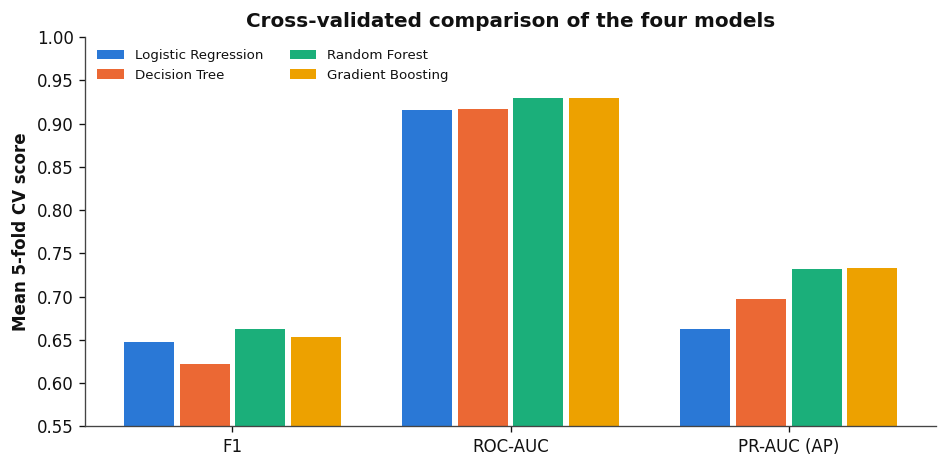

In [ ]:
# Cross-Validation Chart
# Take the mean value from each "mean ± std" cell
cv_means = cv_table[["f1", "ROC-AUC", "PR-AUC (AP)"]].apply(lambda col: col.str.split(" ± ").str[0].astype(float))

# Grouped bar chart
x = np.arange(3)
fig, ax = plt.subplots(figsize=(8, 4))
for i, (name, row) in enumerate(cv_means.iterrows()):
    ax.bar(x + (i - 1.5) * 0.2, row.values, width=0.18, color=colors[i], label=name)
ax.set_xticks(x)
ax.set_xticklabels(["F1", "ROC-AUC", "PR-AUC (AP)"])
ax.set_ylim(0.55, 1.0)
ax.set_ylabel("Mean 5-fold CV score")
ax.set_title("Cross-validated comparison of the four models")
ax.legend(loc="upper left", fontsize=8, frameon=False, ncol=2)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix, classification_report)

# Train each model on the full training set, then score the test set
fitted = {}
test_results = {}
for name, model in models.items():
    pipe = Pipeline([("pre", make_preprocessor()), ("clf", model)])
    if name == "Gradient Boosting":
        pipe.fit(X_train, y_train, clf__sample_weight=sw)
    else:
        pipe.fit(X_train, y_train)
    fitted[name] = pipe
    prob = pipe.predict_proba(X_test)[:, 1]
    pred = (prob >= 0.5).astype(int)
    test_results[name] = {"Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
                          "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
                          "ROC-AUC": roc_auc_score(y_test, prob), "PR-AUC (AP)": average_precision_score(y_test, prob)}

test_table = pd.DataFrame(test_results).T.round(3)
test_table

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC (AP)
Logistic Regression,0.870,0.558,0.814,0.662,0.925,0.677
Decision Tree,0.831,0.478,0.843,0.610,0.913,0.682
Random Forest,0.871,0.558,0.835,0.669,0.931,0.726
Gradient Boosting,0.866,0.545,0.851,0.665,0.938,0.751


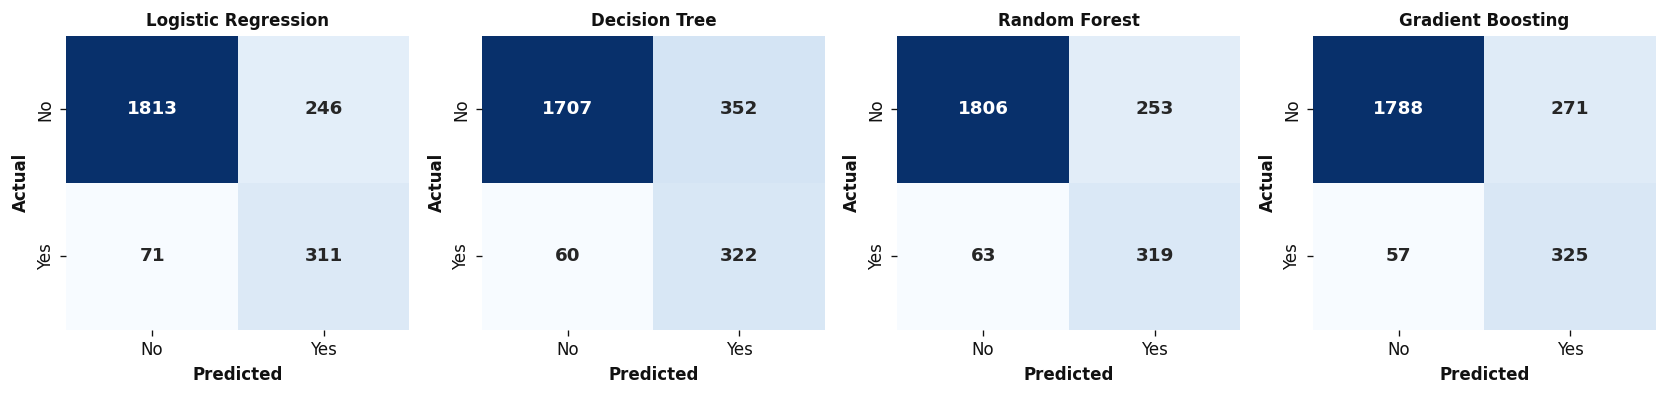

In [ ]:
# Confusion matrix for each model on the test set
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, (name, pipe) in zip(axes, fitted.items()):
    cm = confusion_matrix(y_test, pipe.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cbar=False, ax=ax, annot_kws={"size": 11, "weight": "bold"},
                cmap="Blues",
                xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

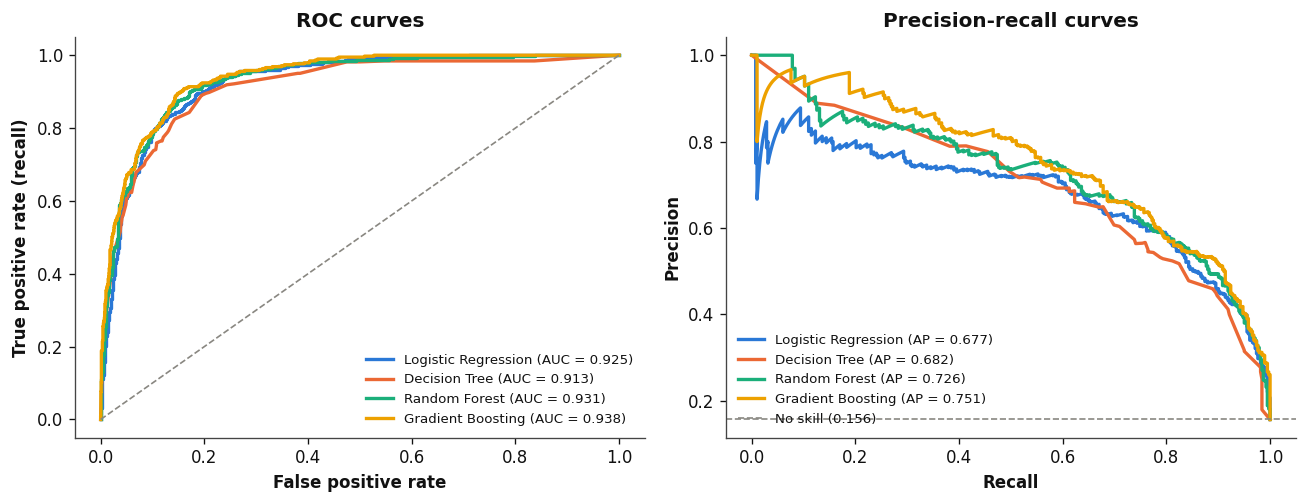

In [ ]:
from sklearn.metrics import roc_curve, precision_recall_curve

# ROC curve (left) and precision-recall curve (right) for each model
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for (name, pipe), col in zip(fitted.items(), colors):
    prob = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    prec, rec, _ = precision_recall_curve(y_test, prob)
    axes[0].plot(fpr, tpr, color=col, lw=2, label=f"{name} (AUC = {test_table.loc[name, 'ROC-AUC']:.3f})")
    axes[1].plot(rec, prec, color=col, lw=2, label=f"{name} (AP = {test_table.loc[name, 'PR-AUC (AP)']:.3f})")

# Reference lines for a model with no skill
axes[0].plot([0, 1], [0, 1], ls="--", color="#898781", lw=1)
axes[1].axhline(y_test.mean(), ls="--", color="#898781", lw=1, label=f"No skill ({y_test.mean():.3f})")

axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("ROC curves")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-recall curves")
for ax in axes:
    ax.legend(fontsize=8, frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [ ]:
# Random Forest results for each class on the test set
best = fitted["Random Forest"]
print(classification_report(y_test, best.predict(X_test), target_names=["No purchase", "Purchase"], digits=3))

              precision    recall  f1-score   support

 No purchase      0.966     0.877     0.920      2059
    Purchase      0.558     0.835     0.669       382

    accuracy                          0.871      2441
   macro avg      0.762     0.856     0.794      2441
weighted avg      0.902     0.871     0.880      2441



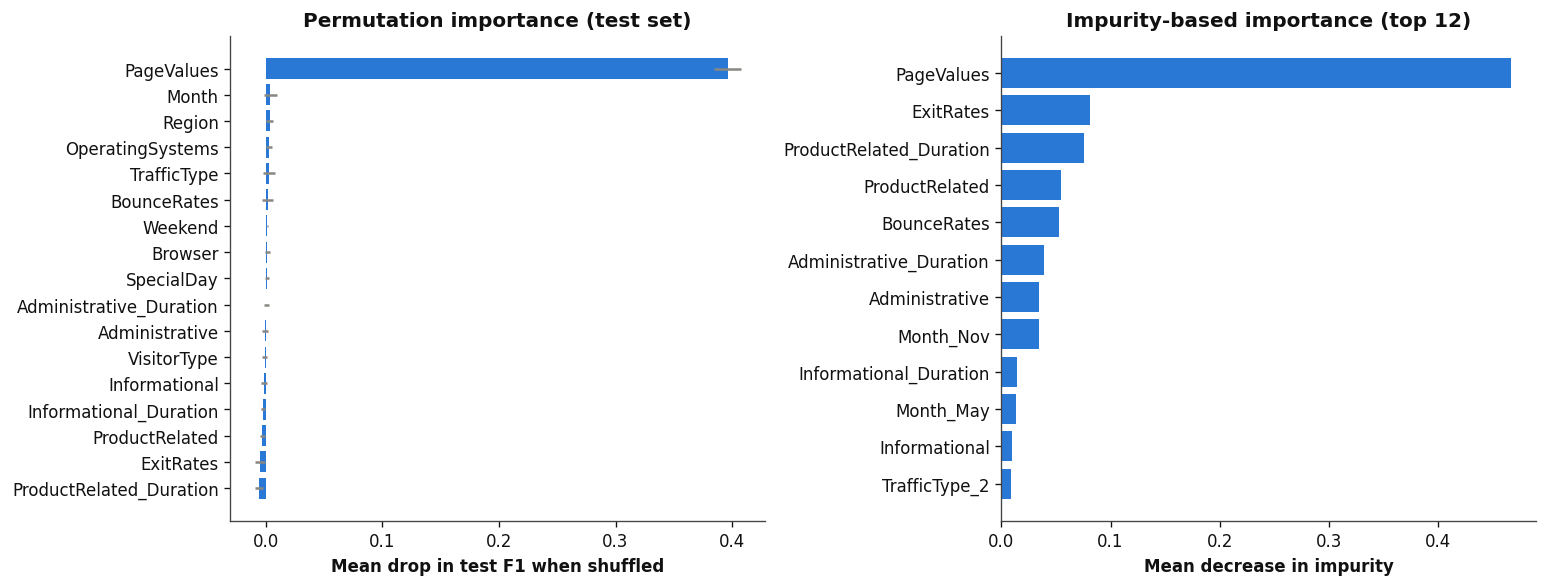

Permutation importance:
PageValues                 0.3961
Month                      0.0038
Region                     0.0031
OperatingSystems           0.0024
TrafficType                0.0024
BounceRates                0.0015
Weekend                    0.0013
Browser                    0.0010
SpecialDay                 0.0008
Administrative_Duration    0.0001
Administrative            -0.0005
VisitorType               -0.0010
Informational             -0.0015
Informational_Duration    -0.0027
ProductRelated            -0.0030
ExitRates                 -0.0051
ProductRelated_Duration   -0.0057
dtype: float64

Impurity-based importance (top 8):
PageValues                 0.4666
ExitRates                  0.0814
ProductRelated_Duration    0.0757
ProductRelated             0.0548
BounceRates                0.0528
Administrative_Duration    0.0393
Administrative             0.0345
Month_Nov                  0.0341
dtype: float64


In [ ]:
from sklearn.inspection import permutation_importance

# Permutation importance: drop in test F1 when one attribute is shuffled
pi = permutation_importance(best, X_test, y_test, scoring="f1", n_repeats=10, random_state=42, n_jobs=-1)
perm = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
perm_std = pd.Series(pi.importances_std, index=X_test.columns)[perm.index]

# Impurity-based importance from the trained forest (top 12 encoded features)
gini = pd.Series(best.named_steps["clf"].feature_importances_,
                 index=best.named_steps["pre"].get_feature_names_out())
gini.index = gini.index.str.split("__").str[-1]
gini = gini.sort_values().tail(12)

# Side-by-side bar charts
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(perm.index, perm.values, xerr=perm_std.values, color=blue, ecolor="#898781")
axes[0].set_xlabel("Mean drop in test F1 when shuffled")
axes[0].set_title("Permutation importance (test set)")
axes[1].barh(gini.index, gini.values, color=blue)
axes[1].set_xlabel("Mean decrease in impurity")
axes[1].set_title("Impurity-based importance (top 12)")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print("Permutation importance:")
print(perm.sort_values(ascending=False).round(4))
print("\nImpurity-based importance (top 8):")
print(gini.sort_values(ascending=False).head(8).round(4))

In [ ]:
# Retrain the same Random Forest without the PageValues column
X_train_np = X_train.drop(columns="PageValues")
X_test_np = X_test.drop(columns="PageValues")
rf_np = Pipeline([("pre", make_preprocessor(skewed=[c for c in skew_cols if c != "PageValues"])),
                  ("clf", models["Random Forest"])])
rf_np.fit(X_train_np, y_train)
prob_np = rf_np.predict_proba(X_test_np)[:, 1]
pred_np = (prob_np >= 0.5).astype(int)

# Compare with the full model
compare = pd.DataFrame({
    "With PageValues": test_table.loc["Random Forest", ["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC (AP)"]],
    "Without PageValues": [precision_score(y_test, pred_np), recall_score(y_test, pred_np), f1_score(y_test, pred_np),
                           roc_auc_score(y_test, prob_np), average_precision_score(y_test, prob_np)]}).round(3)
compare

,With PageValues,Without PageValues
Precision,0.558,0.332
Recall,0.835,0.644
F1,0.669,0.439
ROC-AUC,0.931,0.789
PR-AUC (AP),0.726,0.374
